# 🧠 TP guidé — Comment une IA apprend-elle à dessiner des vêtements ?

### AE · VAE · GAN — Une découverte pas à pas,

<center> Dr Mohammed BOUSMAH EMSI-2026 — bousmah@gmail.com</center>

**Notre mission :** faire apprendre à un ordinateur la forme de vêtements à partir de petites images Fashion-MNIST, puis comparer trois façons de reconstruire ou de fabriquer des images.

**Nos trois personnages :**

| Réseau | Son rôle | Image mentale |
|:--|:--|:--|
| **AE** (autoencodeur) | Résumer puis recopier | Un photocopieur qui apprend |
| **VAE** (autoencodeur variationnel) | Résumer avec une part de hasard, puis générer | Un inventeur qui apprend une carte des possibilités |
| **GAN** (réseau antagoniste) | Fabriquer et critiquer des images | Un dessinateur face à un détective |

✅ **Mode d'emploi :** lis une explication, exécute la cellule Python juste après avec **Maj + Entrée**, puis réponds à la question « À observer ». Commence avec `TRAIN_LIMIT = 10000` pour une première exécution plus légère.

**Prérequis :** Python, PyTorch, torchvision, numpy, pandas et matplotlib. Les données sont téléchargées lors du premier usage. Une connexion Internet peut être nécessaire au premier lancement.

# TP — AE, VAE et GAN : trois façons d'apprendre à générer des images

**Master Intelligence Artificielle · Deep Learning · Fashion-MNIST**  
**Durée indicative :** 3 à 4 heures (ou deux séances)  
**Prérequis :** PyTorch, rétropropagation, BCE/MSE, distributions gaussiennes.

### Objectifs pédagogiques
1. Reconstruire une image avec un **autoencodeur (AE)**.
2. Apprendre un espace latent probabiliste avec un **VAE**.
3. Générer des images à partir d'un bruit aléatoire avec un **GAN**.
4. Comparer reconstruction, échantillonnage, stabilité et diversité.
5. Diagnostiquer un possible *mode collapse*, sans confondre indicateurs et preuve.

> **Important** : les courbes et images seront produites par vos propres expériences. Ce notebook ne prétend pas fournir des mesures déjà obtenues.

## 0 — Installation et environnement

Sur macOS Apple Silicon, PyTorch peut utiliser **MPS**. Sous Linux, il peut utiliser **CUDA**. Sinon, CPU.

Dans un terminal avec `uv` :

```bash
uv add torch torchvision matplotlib numpy pandas ipykernel
uv run python -m ipykernel install --user --name ai-generatif --display-name "Python (AI génératif)"
```

Sélectionnez ensuite le noyau correspondant dans Jupyter. Installez les paquets **en dehors du notebook** si nécessaire.

### 🔎 Avant d'exécuter : préparer l'atelier

L'ordinateur a besoin d'une **boîte à outils** : `torch` pour construire les réseaux, `torchvision` pour accéder aux images et `matplotlib` pour les afficher.

- `SEED = 42` : on fixe le hasard, pour faciliter la reproduction de l'expérience.
- `DEVICE` : on choisit automatiquement le moteur de calcul : **CUDA**, **MPS** (Mac Apple Silicon) ou **CPU**.
- `OUT` : dossier pour sauvegarder les résultats.

**À observer :** quel appareil apparaît après l'exécution ?

In [1]:
import random, time, copy, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
print('PyTorch :', torch.__version__, '| appareil :', DEVICE)
OUT = Path('outputs_ae_vae_gan'); OUT.mkdir(exist_ok=True)

PyTorch : 2.14.1 | appareil : mps


## 1 — Données : Fashion-MNIST

Chaque image en niveaux de gris comporte **28 × 28 pixels** :

$$
\boxed{28\times28=784\ \text{pixels}}
$$

Toutes les images sont normalisées dans l'intervalle :

$$
\boxed{x\in[-1,1]^{1\times28\times28}}
$$

**Pourquoi ?** Les décodeurs AE/VAE et le générateur GAN utilisent `Tanh` : leurs sorties sont donc comprises entre −1 et 1.

Pour AE et VAE, nous utilisons une **MSE** sur les pixels (plutôt qu'une BCE inadaptée à des cibles négatives).

### 🔎 Avant d'exécuter : les réglages de l'expérience

Un **pixel** est un tout petit carré. Une image contient **28 × 28 = 784 pixels**.

La transformation du notebook convertit les intensités des pixels, à l'origine entre 0 et 1, vers l'intervalle **[-1, 1]** :

$$
x_{\mathrm{normalisé}}=2x_{\mathrm{initial}}-1
$$

- `BATCH_SIZE = 128` : le modèle examine 128 images à la fois (sauf éventuellement le dernier lot).
- `EPOCHS_AE`, `EPOCHS_VAE`, `EPOCHS_GAN` : nombre de passages sur tout le jeu d'entraînement.
- `Z_DIM = 16` : résumé de 16 nombres pour AE et VAE.
- `GAN_Z_DIM = 100` : 100 nombres aléatoires pour le générateur GAN.
- `TRAIN_LIMIT = None` : utiliser tout le jeu d'entraînement. Pour un test rapide, remplacer par `10000`.

**À prévoir :** le premier chargement télécharge Fashion-MNIST si nécessaire.

In [2]:
BATCH_SIZE = 128
# Pour un premier test rapide, passer à 10000 ; None utilise les 60000 images.
TRAIN_LIMIT = None
EPOCHS_AE = 8
EPOCHS_VAE = 8
EPOCHS_GAN = 15
Z_DIM = 16       # dimension de l'espace latent AE / VAE
GAN_Z_DIM = 100  # dimension du bruit GAN

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
full_train = datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST('./data', train=False, download=True, transform=transform)
if TRAIN_LIMIT is not None:
    ids = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(SEED))[:TRAIN_LIMIT]
    train_ds = Subset(full_train, ids.tolist())
else:
    train_ds = full_train
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
classes = full_train.classes
print('Apprentissage :', len(train_ds), '| Test :', len(test_ds), '| Classes :', classes)

Apprentissage : 60000 | Test : 10000 | Classes : ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 👀 Observer les données avant d'apprendre

Cette cellule affiche **12 vraies images** de Fashion-MNIST. Les nombres des pixels sont convertis vers `[0, 1]` uniquement pour les afficher plus facilement.

**Question :** un humain peut-il reconnaître la catégorie de chaque vêtement ? L'ordinateur, lui, part de valeurs numériques.

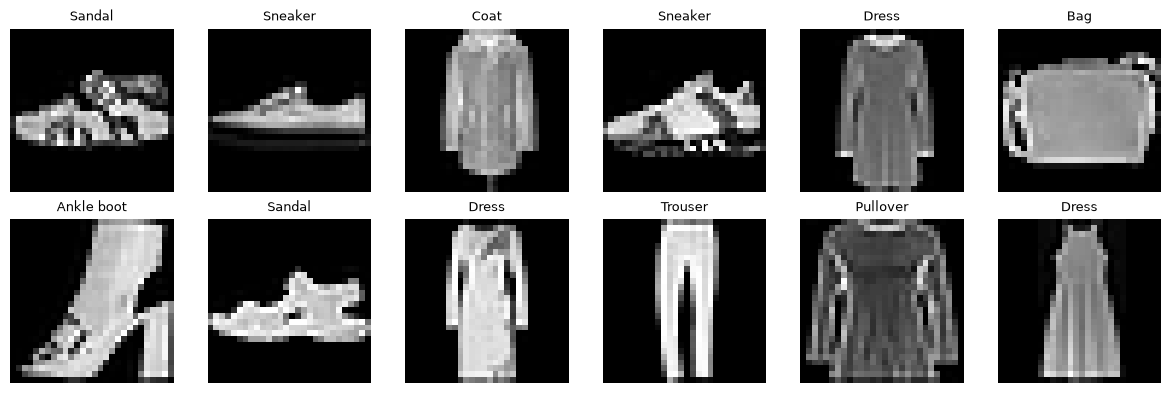

In [3]:
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax, im, label in zip(axes.flat, images[:12], labels[:12]):
    ax.imshow((im.squeeze().numpy()+1)/2, cmap='gray', vmin=0, vmax=1)
    ax.set_title(classes[int(label)], fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 2 — AE : reconstruction déterministe

### 2.1. Principe

L'encodeur transforme une image $x$ en un vecteur latent $z$ ; le décodeur reconstruit une image $\hat{x}$.

$$
\boxed{x\ \xrightarrow{\ E_{\phi}\ }\ z\ \xrightarrow{\ D_{\theta}\ }\ \hat{x}}
$$

- $x$ : image originale ;
- $z$ : représentation latente ;
- $\hat{x}$ : image reconstruite ;
- $\phi,\theta$ : paramètres entraînables des deux réseaux.

### 2.2. Fonction de perte

On minimise l'erreur quadratique moyenne (*Mean Squared Error*, MSE) sur les $B$ images d'un lot et les $P=784$ pixels :

$$
\boxed{
\mathcal{L}_{\mathrm{AE}}
=\frac{1}{BP}\sum_{i=1}^{B}\sum_{j=1}^{P}
\left(x_{ij}-\hat{x}_{ij}\right)^2
}
$$

**À retenir :** un AE apprend à reconstruire. Il n'apprend pas nécessairement une loi permettant de tirer directement de nouveaux vecteurs latents plausibles.

### 🧩 AE : construire un « compresseur-décompresseur »

Pense à une image comme à une longue phrase de **784 nombres**. L'encodeur la résume en seulement **16 nombres**. Puis le décodeur tente de recréer la phrase.

$$
\underbrace{x}_{784\ \text{pixels}}\xrightarrow{\text{encodeur}}\underbrace{z}_{16\ \text{nombres}}\xrightarrow{\text{décodeur}}\underbrace{\hat{x}}_{784\ \text{pixels}}
$$

Dans le code :

- `nn.Flatten()` aligne les pixels en une seule liste.
- `nn.Linear(a,b)` apprend à transformer `a` nombres en `b` nombres.
- `nn.ReLU()` ajoute une transformation non linéaire : sans elle, le réseau serait trop limité.
- `nn.Tanh()` remet les pixels reconstruits dans **[-1, 1]**.
- `forward` décrit le trajet des données dans le réseau.

**Mini-défi :** retrouve les nombres **784 → 256 → 128 → 16** dans la classe `Encoder`.

In [4]:
class Encoder(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                 nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, out_dim))
    def forward(self, x): return self.net(x)

class Decoder(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, 128), nn.ReLU(),
                                 nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 784), nn.Tanh())
    def forward(self, z): return self.net(z).view(-1, 1, 28, 28)

class AE(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.encoder = Encoder(z_dim); self.decoder = Decoder(z_dim)
    def forward(self, x): return self.decoder(self.encoder(x))

ae = AE().to(DEVICE)
print('Paramètres AE :', sum(p.numel() for p in ae.parameters()))

Paramètres AE : 472608


### 🎯 AE : apprendre à réduire ses erreurs

Au début, la copie du vêtement est mauvaise. Le programme mesure l'écart entre les pixels de l'image et ceux de la copie :

$$
\operatorname{MSE}(x,\hat x)=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat x_i)^2
$$

**Traduction :** pour chaque pixel, on calcule la différence, on la met au carré, puis on prend la moyenne. Le but est de rendre ce nombre **petit**.

Chaque lot suit la boucle : **prédire → calculer l'erreur → calculer les gradients → corriger les poids**.

- `loss.backward()` calcule dans quel sens modifier les poids.
- `optimizer.step()` effectue la correction.

**À observer :** la MSE diminue-t-elle d'une époque à l'autre ?

In [ ]:
def train_ae(model, loader, epochs=8, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train(); total = 0; count = 0
        for x, _ in loader:
            x = x.to(DEVICE)
            loss = nn.functional.mse_loss(model(x), x)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * x.size(0); count += x.size(0)
        history.append(total/count)
        print(f'AE   {epoch+1:02d}/{epochs} | MSE={history[-1]:.4f}')
    return history

ae_hist = train_ae(ae, train_loader, EPOCHS_AE)

### ✅ Pause compréhension — AE

1. Pourquoi le modèle passe-t-il de 784 valeurs à seulement 16 ?
2. Le décodeur reçoit-il l'image complète ou son résumé ?
3. Une MSE de 0 signifie-t-elle que la copie est identique à l'original ?

**Réponses :** (1) Pour apprendre une représentation compacte. (2) Il reçoit le code latent. (3) Oui, pour les valeurs comparées, une MSE nulle signifie aucune différence pixel à pixel.

## 3 — VAE : reconstruction probabiliste

### 3.1. L'encodeur apprend une distribution

Pour chaque image $x$, le VAE calcule deux vecteurs :

$$
\boxed{\mu_{\phi}(x)\qquad\text{et}\qquad\log\sigma_{\phi}^{2}(x)}
$$

Ils définissent une loi gaussienne conditionnelle :

$$
q_{\phi}(z\mid x)
=\mathcal{N}\!\left(\mu_{\phi}(x),\ \operatorname{diag}(\sigma_{\phi}^{2}(x))\right)
$$

### 3.2. Astuce de reparamétrisation

On tire d'abord un bruit gaussien indépendant :

$$
\varepsilon\sim\mathcal{N}(0,I)
$$

Puis on construit le vecteur latent :

$$
\boxed{
z=\mu_{\phi}(x)
+\exp\!\left(\frac{1}{2}\log\sigma_{\phi}^{2}(x)\right)\odot\varepsilon
}
$$

Le symbole $\odot$ désigne la multiplication **élément par élément**.

### 3.3. Fonction de perte

La perte combine **reconstruction** et **régularisation de l'espace latent** :

$$
\boxed{\mathcal{L}_{\mathrm{VAE}}=\mathcal{L}_{\mathrm{recon}}+\beta\,\mathcal{L}_{\mathrm{KL}}}
$$

**Terme 1 — Reconstruction :**

$$
\mathcal{L}_{\mathrm{recon}}
=\frac{1}{BP}\sum_{i=1}^{B}\sum_{j=1}^{P}
(x_{ij}-\hat{x}_{ij})^2
$$

**Terme 2 — Divergence de Kullback–Leibler :**

$$
\mathcal{L}_{\mathrm{KL}}
=\frac{1}{B}\sum_{i=1}^{B}
D_{\mathrm{KL}}\!\left(q_{\phi}(z\mid x_i)\,\|\,\mathcal{N}(0,I)\right)
$$

Dans le cas gaussien diagonal, le terme se calcule exactement :

$$
\boxed{
\mathcal{L}_{\mathrm{KL}}
=-\frac{1}{2B}\sum_{i=1}^{B}\sum_{k=1}^{d_z}
\left(1+\log\sigma_{ik}^{2}-\mu_{ik}^{2}-\sigma_{ik}^{2}\right)
}
$$

**Notation :** $B$ = taille du lot ; $P=784$ = nombre de pixels ; $d_z$ = dimension latente ; $\beta$ = pondération de la régularisation.

> **Remarque pédagogique :** la MSE est ici *moyennée* sur les pixels, tandis que la KL est *sommée* sur les dimensions latentes puis moyennée sur le lot. Ces termes n'ont pas la même échelle ; `BETA` est un réglage pédagogique de type $\beta$-VAE, pas la calibration d'une ELBO avec modèle d'observation entièrement spécifié.

### 🎲 VAE : un résumé qui laisse une place au hasard

L'AE fabrique un résumé précis. Le VAE fabrique les paramètres d'une **distribution de résumés possibles**.

Il produit :

- `mu` (μ) : le centre des possibilités.
- `logvar` : le logarithme de la variance. On utilise ce nombre pour retrouver l'écart-type σ.

La formule de rééchantillonnage est :

$$
z=\mu+\sigma\varepsilon,\qquad
\sigma=\exp\left(\frac{\mathrm{logvar}}{2}\right),\quad
\varepsilon\sim\mathcal N(0,I)
$$

**Exemple à une dimension :** si μ = 5, σ = 2 et ε = 0,5, alors z = 6. Le code est donc légèrement différent du centre.

Dans cette cellule, repère `torch.randn_like(mu)` : c'est là que le hasard entre dans le VAE.

**Attention :** un VAE ne génère pas automatiquement des images réalistes ; tout dépend de la qualité de l'entraînement.

In [ ]:
BETA = 0.001   # À faire varier : 0, 0.001, 0.01, 0.1

class VAE(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.backbone = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                      nn.Linear(256, 128), nn.ReLU())
        self.mu = nn.Linear(128, z_dim)
        self.logvar = nn.Linear(128, z_dim)
        self.decoder = Decoder(z_dim)
    def encode(self, x):
        h = self.backbone(x)
        return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        eps = torch.randn_like(mu)
        return mu + torch.exp(0.5 * logvar) * eps
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

vae = VAE().to(DEVICE)
print('Paramètres VAE :', sum(p.numel() for p in vae.parameters()))

### ⚖️ VAE : apprendre avec deux objectifs

Le VAE doit : **(1) bien reconstruire** les vêtements et **(2) organiser son espace latent** pour qu'on puisse y tirer des codes aléatoires.

Sa perte est :

$$
\mathcal L_{\mathrm{VAE}}=\underbrace{\mathcal L_{\mathrm{reconstruction}}}_{\text{qualité de la copie}}+\beta\underbrace{D_{\mathrm{KL}}\bigl(q(z|x)\,\|\,p(z)\bigr)}_{\text{régularisation de l'espace latent}}
$$

Le terme **KL** pénalise un écart trop important avec une distribution normale de référence. C'est comme demander au VAE de garder ses résumés dans un espace bien organisé.

`BETA = 0.001` dose le compromis : une grande valeur donne davantage de poids à cette organisation, parfois au détriment de la netteté des copies.

**À observer :** trois valeurs s'affichent (`total`, `recon`, `KL`). La perte totale combine reconstruction et KL pondérée par β. 

In [ ]:
def vae_loss(xhat, x, mu, logvar, beta=BETA):
    recon = nn.functional.mse_loss(xhat, x)
    kl = -0.5 * torch.sum(1 + logvar - mu.square() - logvar.exp(), dim=1).mean()
    return recon + beta*kl, recon, kl

def train_vae(model, loader, epochs=8, lr=1e-3, beta=BETA):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'total': [], 'reconstruction': [], 'kl': []}
    for epoch in range(epochs):
        model.train(); sums = np.zeros(3); count = 0
        for x, _ in loader:
            x = x.to(DEVICE)
            xhat, mu, logvar = model(x)
            loss, recon, kl = vae_loss(xhat, x, mu, logvar, beta)
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            sums += np.array([loss.item(), recon.item(), kl.item()])*x.size(0)
            count += x.size(0)
        for key, value in zip(history, sums/count): history[key].append(float(value))
        print(f'VAE  {epoch+1:02d}/{epochs} | total={history["total"][-1]:.4f} '
              f'| recon={history["reconstruction"][-1]:.4f} | KL={history["kl"][-1]:.3f}')
    return history

vae_hist = train_vae(vae, train_loader, EPOCHS_VAE)

### ✅ Pause compréhension — VAE

1. Quelle est la différence essentielle entre le code de l'AE et celui du VAE ?
2. Dans `z = μ + σ × ε`, que représente ε ?
3. Pourquoi ajouter un terme KL à la perte ?

**Réponses :** (1) Le VAE apprend une distribution et échantillonne un code. (2) Un tirage aléatoire normal. (3) Pour encourager un espace latent compatible avec la distribution de référence.

## 4 — GAN : compétition entre générateur et discriminateur

### 4.1. Deux réseaux, deux objectifs

Le **générateur** transforme un bruit aléatoire $z$ en image synthétique :

$$
\boxed{z\sim\mathcal{N}(0,I)\qquad\longrightarrow\qquad x_{\mathrm{fake}}=G(z)}
$$

Le **discriminateur** reçoit une image $x$ et tente d'en estimer l'origine :

$$
\boxed{D(x)\in[0,1]}
$$

$D(x)$ désigne ici le **score après sigmoïde**. Dans notre code, le réseau renvoie des *logits*, convertis implicitement par `BCEWithLogitsLoss`.

### 4.2. Perte du discriminateur

Le discriminateur cherche à attribuer un score élevé aux images réelles et faible aux images générées :

$$
\boxed{
\mathcal{L}_D=-\frac12\left(
\mathbb{E}_{x\sim p_{\mathrm{data}}}\![\log D(x)]
+\mathbb{E}_{z\sim p_z}\![\log(1-D(G(z)))]
\right)
}
$$

Le facteur $\tfrac12$ correspond à la **moyenne des deux termes BCE** dans notre code.

### 4.3. Perte du générateur

Le générateur veut que les images qu'il crée soient classées comme réelles :

$$
\boxed{
\mathcal{L}_G
=-\mathbb{E}_{z\sim p_z}\![\log D(G(z))]
}
$$

C'est l'objectif **non saturant**, fréquemment utilisé en pratique.

### 4.4. Alternance des mises à jour

1. **Entraîner D** sur des images réelles et sur $G(z)$ **détaché** (`detach()`).
2. **Entraîner G** en laissant les gradients passer à travers D, **sans changer les poids de D**.
3. Répéter ces deux opérations sur les lots de données.

> **Point d'attention :** la courbe des pertes GAN ne se lit pas comme celle d'un classificateur supervisé classique : les objectifs des deux modèles évoluent en compétition.

### 🥊 GAN : deux réseaux se défient

Imagine deux élèves :

- Le **générateur G** dessine de fausses chaussures à partir de 100 nombres tirés au hasard.
- Le **discriminateur D** essaie de distinguer les vrais vêtements des faux.

$$
\underbrace{z}_{100\ \text{nombres}}\xrightarrow{G}\underbrace{G(z)}_{28\times28\ \text{pixels}}\xrightarrow{D}\underbrace{D(G(z))}_{\text{score « vrai »}}
$$

Le discriminateur renvoie ici un **logit** (score brut), pas directement une probabilité. On peut appliquer la fonction `sigmoid` pour obtenir une valeur comprise entre 0 et 1.

**Mini-défi :** retrouve `Linear(z_dim, 256)` dans `Generator` et `Linear(256, 1)` dans `Discriminator`.

In [ ]:
class Generator(nn.Module):
    def __init__(self, z_dim=GAN_Z_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 784), nn.Tanh()
        )
    def forward(self, z): return self.net(z).view(-1, 1, 28, 28)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1)
        )
    def forward(self, x): return self.net(x)  # logits

G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)
print('Paramètres G :', sum(p.numel() for p in G.parameters()))
print('Paramètres D :', sum(p.numel() for p in D.parameters()))

### 🔁 GAN : comment se déroule une manche ?

**Manche A : on entraîne D.** On lui montre des vêtements authentiques (étiquette **1**) et des vêtements fabriqués (étiquette **0**). On corrige ses erreurs.

**Manche B : on entraîne G.** On lui demande de créer des images que D jugera authentiques. Cette fois, les poids de D restent fixes.

La fonction `BCEWithLogitsLoss` mesure l'erreur de classification à partir des **logits**.

- `fake = G(z).detach()` : lors de l'entraînement de D, on n'envoie pas les gradients vers G.
- `requires_grad_(False)` : on fige temporairement les paramètres de D durant l'entraînement de G.
- `fixed_noise` : on réutilise exactement les mêmes 64 codes pour voir si les créations progressent au fil des époques.

**À observer :** les pertes de G et D peuvent fluctuer ; leur baisse simultanée n'est pas nécessaire pour avoir de meilleures images.

In [ ]:
fixed_noise = torch.randn(64, GAN_Z_DIM, device=DEVICE)

def train_gan(G, D, loader, epochs=15, lr=2e-4):
    bce = nn.BCEWithLogitsLoss()
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    hist = {'D': [], 'G': [], 'D_real': [], 'D_fake': []}
    snapshots = {}
    for epoch in range(epochs):
        G.train(); D.train(); acc = np.zeros(4); seen = 0
        for real, _ in loader:
            real = real.to(DEVICE); n = len(real)
            ones = torch.ones(n, 1, device=DEVICE)
            zeros = torch.zeros(n, 1, device=DEVICE)
            # Mise à jour D : ne pas entraîner G
            z = torch.randn(n, GAN_Z_DIM, device=DEVICE)
            fake = G(z).detach()
            d_real = D(real)
            d_fake = D(fake)
            loss_d = (bce(d_real, ones) + bce(d_fake, zeros))/2
            opt_d.zero_grad(set_to_none=True)
            loss_d.backward(); opt_d.step()
            # Mise à jour G : gradient à travers D mais paramètres D figés
            for p in D.parameters(): p.requires_grad_(False)
            z = torch.randn(n, GAN_Z_DIM, device=DEVICE)
            fake = G(z)
            loss_g = bce(D(fake), ones)
            opt_g.zero_grad(set_to_none=True)
            loss_g.backward(); opt_g.step()
            for p in D.parameters(): p.requires_grad_(True)
            acc += n*np.array([loss_d.item(), loss_g.item(),
                               torch.sigmoid(d_real.detach()).mean().item(),
                               torch.sigmoid(d_fake.detach()).mean().item()])
            seen += n
        for key, value in zip(hist, acc/seen): hist[key].append(float(value))
        G.eval()
        with torch.no_grad(): snapshots[epoch+1] = G(fixed_noise).cpu().clone()
        print(f'GAN  {epoch+1:02d}/{epochs} | D={hist["D"][-1]:.3f} '
              f'| G={hist["G"][-1]:.3f} | D(real)={hist["D_real"][-1]:.3f} '
              f'| D(fake)={hist["D_fake"][-1]:.3f}')
    return hist, snapshots

gan_hist, gan_snapshots = train_gan(G, D, train_loader, EPOCHS_GAN)

### ✅ Pause compréhension — GAN

1. Qui fabrique les images : G ou D ?
2. Pourquoi faut-il montrer à D de vraies images ?
3. Pourquoi bloque-t-on le gradient vers G pendant la mise à jour de D ?

**Réponses :** (1) G. (2) Pour apprendre ce qui ressemble à une vraie image. (3) Afin d'entraîner uniquement D durant cette étape.

## 5 — Comparaison visuelle : original, AE, VAE

Le VAE est ici évalué à partir de **sa moyenne latente** pour une reconstruction reproductible, tandis que le modèle reste stochastique en apprentissage.

### 🖼️ Comparer les copies

Trois lignes vont apparaître :

1. **Original** : le vrai vêtement, jamais utilisé pour entraîner le modèle dans ce test.
2. **AE** : le vêtement recopié par l'autoencodeur.
3. **VAE** : la reconstruction du VAE réalisée avec son code moyen μ (sans tirer au hasard).

**Question :** les copies sont-elles plus floues que les originaux ? Essaie de repérer les détails perdus.

In [ ]:
ae.eval(); vae.eval()
x, y = next(iter(test_loader)); x = x[:10].to(DEVICE)
with torch.no_grad():
    rec_ae = ae(x)
    mu, logvar = vae.encode(x)
    rec_vae = vae.decoder(mu)

fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for j, samples in enumerate([x, rec_ae, rec_vae]):
    for i, im in enumerate(samples):
        axes[j, i].imshow(((im.detach().cpu().squeeze()+1)/2).clamp(0,1), cmap='gray', vmin=0, vmax=1)
        axes[j, i].axis('off')
for ax, label in zip(axes[:,0], ['Original', 'AE', 'VAE']):
    ax.text(-0.2, 0.5, label, transform=ax.transAxes, ha='right', va='center', fontweight='bold')
plt.suptitle('Reconstruction sur des données de test'); plt.tight_layout(); plt.show()

## 6 — Comparaison de la génération : VAE et GAN

Pour générer une image, on tire un vecteur latent :

$$
\boxed{z\sim\mathcal{N}(0,I)}
$$

Puis on le décode avec le **décodeur du VAE** ou avec le **générateur du GAN** :

$$
\boxed{x_{\mathrm{VAE}}=D_{\theta}(z)\qquad ;\qquad x_{\mathrm{GAN}}=G(z)}
$$

**AE :** contrairement au VAE et au GAN, il n'impose pas de loi d'échantillonnage à son espace latent. Échantillonner une gaussienne pour générer avec un AE classique peut fonctionner dans certains cas, mais n'est pas garanti.

### ✨ Faire apparaître des vêtements à partir du hasard

Pour VAE et GAN, on peut partir d'un code tiré de la distribution normale :

$$
z\sim\mathcal N(0,I)
$$

Le VAE transforme ce code en image avec son **décodeur** ; le GAN utilise son **générateur**.

La cellule essaie aussi le décodeur de l'AE avec un code aléatoire : **c'est un test exploratoire**, car rien ne garantit qu'un AE standard puisse produire des images plausibles ainsi.

**À observer :** les trois grilles ont-elles le même niveau de variété et de netteté ?

In [ ]:
def show_images(x, title, nrow=8):
    grid = make_grid(((x.detach().cpu()+1)/2).clamp(0,1), nrow=nrow, padding=2)
    plt.figure(figsize=(9, 9 if len(x)>32 else 5))
    plt.imshow(grid.permute(1,2,0)); plt.title(title); plt.axis('off'); plt.show()

vae.eval(); G.eval(); ae.eval()
with torch.no_grad():
    vae_gen = vae.decoder(torch.randn(64, Z_DIM, device=DEVICE))
    gan_gen = G(torch.randn(64, GAN_Z_DIM, device=DEVICE))
    ae_unconstrained = ae.decoder(torch.randn(64, Z_DIM, device=DEVICE))
show_images(vae_gen, '64 images générées par VAE')
show_images(gan_gen, '64 images générées par GAN')
show_images(ae_unconstrained, 'AE : échantillonnage gaussien naïf (non garanti)')

## 7 — Dynamique d'apprentissage et *mode collapse*

Conservez le **même bruit latent** à chaque époque pour suivre l'évolution des 64 images. Attention : une répétition visuelle n'est qu'un indice de *mode collapse* ; pour une évaluation quantitative robuste, utiliser un classifieur indépendant et des métriques de diversité, voire une étude de couverture des modes.

### 🎞️ Regarder le GAN progresser dans le temps

On montre les images produites à plusieurs époques avec **exactement les mêmes nombres de départ** (`fixed_noise`). Ainsi, toute différence vient principalement de l'apprentissage du générateur.

**Question :** au début, vois-tu surtout du bruit ? À la fin, les formes sont-elles plus reconnaissables ?

In [ ]:
checkpoints = sorted(set([1, max(1,EPOCHS_GAN//4), max(1,EPOCHS_GAN//2), EPOCHS_GAN]))
fig, axes = plt.subplots(1, len(checkpoints), figsize=(4*len(checkpoints),4.5))
if len(checkpoints)==1: axes=[axes]
for ax, ep in zip(axes, checkpoints):
    grid = make_grid((gan_snapshots[ep][:16]+1).clamp(0,2)/2, nrow=4, padding=1)
    ax.imshow(grid.permute(1,2,0)); ax.axis('off'); ax.set_title(f'Époque {ep}')
plt.suptitle('Évolution du générateur : bruit latent fixé'); plt.tight_layout(); plt.show()

### 📈 Lire les courbes sans se tromper

**Graphique de gauche :** l'AE et le VAE utilisent ici un terme d'erreur de reconstruction MSE comparable. Plus bas signifie des copies globalement plus proches en moyenne.

**Graphique de droite :** les pertes de G et D correspondent à un jeu de compétition. **Ne les compare pas numériquement à la MSE** : elles ne mesurent pas la même chose.

**Mini-défi :** qu'arrive-t-il aux images si une perte baisse, mais que le résultat visuel semble mauvais ? La courbe seule ne suffit pas.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13,4))
ax[0].plot(np.arange(1,len(ae_hist)+1), ae_hist, label='AE : MSE')
ax[0].plot(np.arange(1,len(vae_hist['reconstruction'])+1), vae_hist['reconstruction'], label='VAE : MSE')
ax[0].set_title('Reconstruction (termes MSE comparables)')
ax[0].set_xlabel('Époque'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(np.arange(1,len(gan_hist['D'])+1), gan_hist['D'], label='D')
ax[1].plot(np.arange(1,len(gan_hist['G'])+1), gan_hist['G'], label='G')
ax[1].set_title('GAN : pertes adversariales (non comparables à MSE)')
ax[1].set_xlabel('Époque'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8 — Explorer l'espace latent du VAE

Nous visualisons deux coordonnées de la moyenne latente :

$$
\boxed{\big(\mu_1(x),\mu_2(x)\big)}
$$

**Important :** si `Z_DIM` est supérieur à 2, ce graphique n'est qu'une **projection sur deux axes**, pas une carte complète de l'espace latent.

Pour créer une véritable carte latente 2D, réentraîner le VAE avec `Z_DIM = 2` puis explorer une grille de points.

### 🗺️ Explorer la « carte secrète » du VAE

Chaque vêtement possède un code latent de **16 nombres**. Ici, on affiche **seulement les deux premières coordonnées** du centre μ pour dessiner une carte en 2D.

- Un **point** représente un vêtement.
- Une **couleur** représente sa catégorie.
- Des points proches peuvent correspondre à des codes similaires.

**Attention :** ce graphique n'est qu'une projection partielle de 16 dimensions ; deux points peuvent paraître proches sur le graphique sans l'être dans tout l'espace latent.

**Question :** y a-t-il des regroupements de couleurs ?

In [ ]:
vae.eval(); all_mu=[]; all_y=[]
with torch.no_grad():
    for batch_x, batch_y in test_loader:
        mu, _ = vae.encode(batch_x.to(DEVICE))
        all_mu.append(mu.cpu()); all_y.append(batch_y)
        if sum(len(b) for b in all_y)>=2000: break
mus = torch.cat(all_mu)[:2000].numpy()
ys = torch.cat(all_y)[:2000].numpy()
plt.figure(figsize=(8,6))
sc=plt.scatter(mus[:,0], mus[:,1], c=ys, cmap='tab10', s=8, alpha=.65, vmin=-.5, vmax=9.5)
plt.colorbar(sc, ticks=range(10), label='Classe Fashion-MNIST')
plt.xlabel('μ₁'); plt.ylabel('μ₂'); plt.title('VAE — projection sur deux coordonnées latentes')
plt.grid(alpha=.2); plt.show()

## 9 — Bilan reproductible

Évaluons la MSE de reconstruction sur le **jeu de test** pour AE et VAE. Un GAN standard n'a pas d'encodeur ni de reconstruction conditionnée par l'image, donc on n'affiche pas de MSE GAN. **Ne classez pas les modèles uniquement par les pertes**, qui ne mesurent pas les mêmes tâches.

### 🧪 Conclusion de l'expérience : tester sans tricher

On évalue l'AE et le VAE sur **les images de test** : elles n'ont pas été utilisées pour mettre à jour leurs poids.

La **MSE de reconstruction** compare pixel par pixel les originaux et les copies. Un GAN classique n'ayant pas d'encodeur d'image dans ce TP, on ne peut pas mesurer pour lui cette même reconstruction directe.

La cellule sauvegarde aussi un fichier CSV avec le tableau récapitulatif et un fichier `.pt` contenant les poids des modèles.

**Important :** pour juger la qualité de génération, il faudrait aussi étudier visuellement la diversité et éventuellement utiliser d'autres métriques adaptées.

In [ ]:
@torch.no_grad()
def eval_reconstruction(model, loader, is_vae=False):
    model.eval(); total=0; count=0
    for x,_ in loader:
        x=x.to(DEVICE)
        if is_vae:
            mu, _ = model.encode(x)
            pred = model.decoder(mu)
        else:
            pred = model(x)
        total += nn.functional.mse_loss(pred,x,reduction='sum').item()
        count += x.numel()
    return total/count

summary = pd.DataFrame([
    {'Modèle':'AE', 'MSE test reconstruction': eval_reconstruction(ae,test_loader), 'Échantillonnage prior':'Non garanti'},
    {'Modèle':'VAE', 'MSE test reconstruction': eval_reconstruction(vae,test_loader,True), 'Échantillonnage prior':'Oui'},
    {'Modèle':'GAN', 'MSE test reconstruction': np.nan, 'Échantillonnage prior':'Oui'}
])
display(summary)
summary.to_csv(OUT/'comparaison.csv', index=False)
torch.save({'AE':ae.state_dict(),'VAE':vae.state_dict(),'G':G.state_dict(),'D':D.state_dict()}, OUT/'modeles.pt')
print('Résultats enregistrés dans', OUT.resolve())

## 10 — Exercices et questions de réflexion

**Exercice 1 — Compréhension.** Pourquoi `fake.detach()` est-il nécessaire dans la mise à jour du discriminateur ? Pourquoi le générateur reçoit-il un label cible `1` pendant son apprentissage ?

**Exercice 2 — Capacité latente.** Tester `Z_DIM=2`, `16`, puis `64` (réexécuter les définitions et entraînements). Comment varient reconstruction, régularisation et qualité de l'échantillonnage ?

**Exercice 3 — β-VAE.** Tester `BETA = 0`, `0.001`, `0.01`, `0.1`. Comparer les termes `reconstruction` et `KL` **séparément**. Discuter le phénomène de *posterior collapse*.

**Exercice 4 — Stabilité GAN.** Tester trois valeurs de `lr` et plusieurs époques. Identifier les symptômes d'un discriminateur trop puissant et d'un générateur insuffisamment diversifié. Ne pas tirer de conclusions uniquement à partir des pertes.

**Exercice 5 — Diversité.** Proposer un protocole : entraîner un classifieur Fashion-MNIST **indépendant** sur les images réelles, classifier 1 000 images générées et mesurer l'histogramme des 10 classes. Expliquer pourquoi ce proxy ne suffit pas à détecter tous les cas de *mode collapse*.

**Exercice 6 — Synthèse scientifique.** Expliquer, en 150 mots, pourquoi le VAE utilise la divergence de Kullback–Leibler et pourquoi le GAN n'en a pas besoin dans sa formulation standard.

### Grille d'analyse à remettre

| Critère | AE | VAE | GAN |
|---|---|---|---|
| Reconstruction d'une image donnée | À mesurer | À mesurer | Non native |
| Génération sans image d'entrée | Non garantie | Oui | Oui |
| Qualité visuelle des échantillons | À observer | À observer | À observer |
| Diversité | À analyser | À analyser | À analyser |
| Stabilité / difficulté | À commenter | À commenter | À commenter |

**Livrables :** notebook exécuté, courbes, grilles d'images, tableau d'interprétation et courte conclusion argumentée. 

### Références
- Kingma & Welling, *Auto-Encoding Variational Bayes* (2013/2014).
- Goodfellow et al., *Generative Adversarial Nets* (2014).
- Radford et al., *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks* (2015/2016).

---
## 🎓 Fiche de révision — Les 10 mots à connaître

| Mot | Explication simple |
|:--|:--|
| **Pixel** | Un tout petit carré de l'image |
| **Neurone artificiel** | Un calcul qui combine des nombres, souvent suivi d'une activation |
| **Poids** | Des nombres que le réseau ajuste pour apprendre |
| **Encodeur** | Transforme une image en résumé |
| **Décodeur** | Transforme un résumé en image |
| **Espace latent** | Espace mathématique des résumés appris |
| **Époque** | Un passage complet sur le jeu d'entraînement |
| **MSE** | Mesure moyenne de l'erreur entre pixels |
| **Gradient** | Indique comment faire évoluer les paramètres pour diminuer une perte |
| **Génération** | Création d'une image à partir d'un code, souvent aléatoire |

### 🧠 Le grand bilan

- **AE :** image → résumé → copie.
- **VAE :** image → distribution de résumés → copie, ou code aléatoire → nouvelle image.
- **GAN :** hasard → générateur → fausse image ; discriminateur → critique ; le jeu entraîne les deux.

### ✍️ Mini-projet pour aller plus loin

Lance d'abord le TP avec `TRAIN_LIMIT = 10000`. Puis compare les résultats avec 8 et 15 époques pour l'AE ou le VAE. Note ce qui change pour la **MSE**, le **temps d'entraînement** et les **images**. Dans ton rapport, distingue ce que tu observes de ce que tu supposes.

**Question finale :** si tu veux copier fidèlement une image existante, quel modèle choisirais-tu ? Et si tu veux créer de nouvelles images à partir du hasard ? Explique pourquoi.